In [1]:
import pickle
import os

import numpy as np
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

import models.vgg as models

torch.set_printoptions(sci_mode=False)

import lrp
from models.lrp_converter import convert

from PIL import Image

from utils import get_device, get_dataset, heatmap, project

/home/furbyjl/anaconda3/envs/playing_cards/lib/python3.10/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
device = get_device(cpu=True)

N_CONCEPT, N_CLASSES, val_loader, concept_index_to_string = get_dataset("poker", return_points=False, return_orig=True, return_path=False, shuffle=True)

XtoCtoY = models.End2EndModel(num_classes=N_CLASSES, num_concepts=N_CONCEPT, imagenet_weights=False, use_sigmoid=True, model_version="11_bn", use_modulelist=False)
XtoCtoY.load_state_dict(torch.load("./../saves/converted/sequential-three-seed-46.pth"))
XtoCtoY.to(device)
XtoCtoY.eval()

print("model loaded")

Device: cpu Quadro RTX 6000
model loaded


In [3]:
XtoC = XtoCtoY.x_to_c_model
XtoC.eval()
print(XtoC)

VGG(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (12): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (13): ReLU(inplace=True)
    (14): MaxPool2d(ke

True image size (channels, width, height): torch.Size([3, 299, 299])
True  image concepts: tensor([0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 1., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])


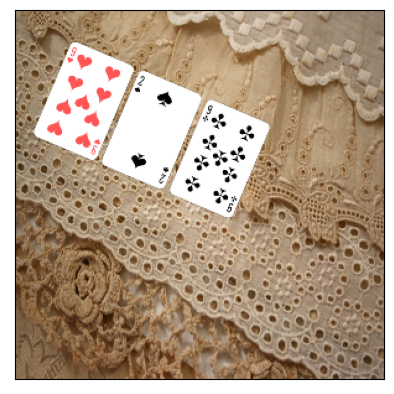

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


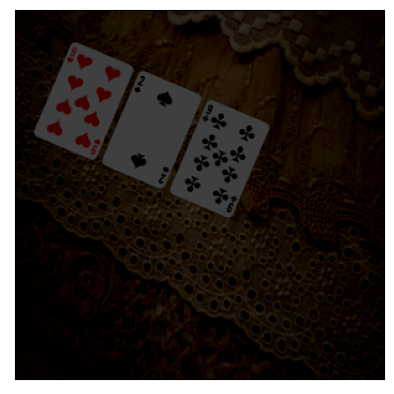

In [4]:
imageId = 7

images, labels, concepts, extra = next(iter(val_loader))
orig_imgs = extra["orig_img"]
image, label = images[imageId].to(device), labels[imageId].to(device)

# print / show input
print("True image size (channels, width, height):", image.size())
print("True  image concepts:", concepts[imageId])

plt.xticks([])
plt.yticks([])
plt.imshow(orig_imgs[imageId].squeeze().permute(1, 2, 0))
plt.show()

plt.xticks([])
plt.yticks([])
plt.imshow(images[imageId].squeeze().permute(1, 2, 0))
plt.show()

In [5]:
image, label = images[imageId].to(device), labels[imageId].to(device)
image = image.unsqueeze(0)
image.requires_grad_(True)
image.grad = None

# get model prediction and LRP map for classification
prediction = XtoC(image)

pred_concepts_readable = torch.nn.Sigmoid()(prediction)

#pred_concepts_readable = torch.nn.Sigmoid()(prediction)
print("Predicted concepts:", pred_concepts_readable)

# print concept as string if prediction is >= 0.5
for idx, i in enumerate(pred_concepts_readable[0]):
    if i.item() >= 0.5:
        print(f"id: {idx},", f"concept name: {concept_index_to_string(idx)},", f"sig value: {i.item()}")

Predicted concepts: tensor([[    0.0000,     0.0000,     0.0000,     1.0000,     0.0000,     0.0000,
             0.0000,     0.0000,     0.0000,     0.0000,     0.0000,     0.0000,
             0.0000,     0.0000,     0.0000,     0.0000,     0.0000,     0.0000,
             0.0000,     0.0000,     0.0000,     0.0000,     0.0000,     0.0000,
             0.0000,     0.0000,     0.0001,     0.0000,     1.0000,     0.0000,
             1.0000,     0.0000,     0.0000,     0.0000,     0.0000,     0.0000,
             0.0000,     0.0000,     0.0000,     0.0000,     0.0000,     0.0000,
             0.0000,     0.0000,     0.0000,     0.0000,     0.0000,     0.0000,
             0.0000,     0.0000,     0.0000,     0.0000]],
       grad_fn=<SigmoidBackward0>)
id: 3, concept name: 2S, sig value: 1.0
id: 28, concept name: 9C, sig value: 0.9999998807907104
id: 30, concept name: 9H, sig value: 1.0


In [6]:
import numpy as np
import matplotlib.pyplot as plt
from captum.attr import IntegratedGradients, Saliency, GuidedGradCam
from captum.attr import NoiseTunnel
from captum.attr import visualization as viz

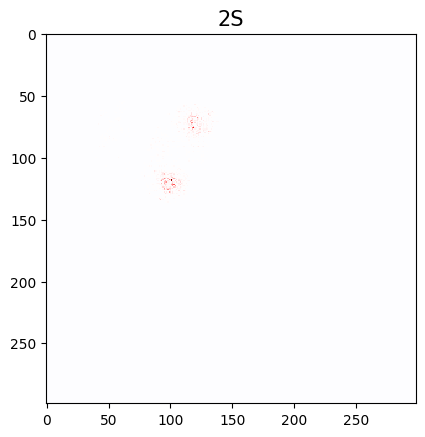

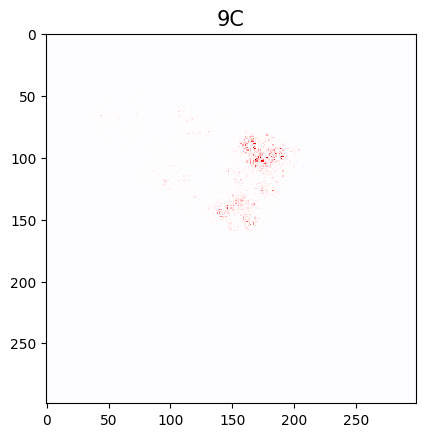

In [ ]:
# A single figure is defined as putting this in a loop quickly uses up all system memory.
# This figure is reused for all plots
ig = IntegratedGradients(XtoC)
nt = NoiseTunnel(ig)

guided_gc = GuidedGradCam(XtoC, XtoC.classifier[0])

image, label = images[imageId].to(device), labels[imageId].to(device)
image = image.unsqueeze(0).to(device)
image.requires_grad_(True)
image.grad = None  # Reset gradient

baselines = image * 0

outputs = XtoC(image)

pred_concepts_readable = torch.nn.Sigmoid()(prediction)

for index in range(outputs.size(1)):
	if pred_concepts_readable[0][index].item() >= 0.5:
		# get saliecy maps for each concept
		filter_out = torch.zeros_like(outputs)
		filter_out[:,index] += 1

		fig, ax = plt.subplots(1)

		"""
		attribution = ig.attribute(
			image,
			target=int(index),
			baselines=baselines,
		)
		"""

		attribution = nt.attribute(
			image,
			target=int(index),
			baselines=baselines,
			nt_type='smoothgrad_sq',
			nt_samples=25,
			internal_batch_size=25,
			stdevs=0.0
		)

		"""
		attribution = guided_gc.attribute(
			image,
			target=int(index),
		)
		"""

		attr = heatmap(attribution, cmap_name="seismic")

		ax.imshow(attr.squeeze(), cmap="seismic", interpolation='none')

		#plt.xticks([])
		#plt.yticks([])
		plt.title(label=concept_index_to_string(index), fontsize=15)
		#plt.imshow(attr.squeeze(), cmap='seismic')
		#plt.savefig(f'temp/{i}.png')
		plt.show()

		plt.close()